In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")

print("Paths configured successfully.")

Paths configured successfully.


In [3]:
customers = pd.read_csv(
   Clean_Data_Path / r"customers_clean.csv"
)

orders = pd.read_csv(
    Clean_Data_Path / r"orders_clean.csv"
)

order_items = pd.read_csv(
    Clean_Data_Path / r"order_items_clean.csv"
)

products = pd.read_csv(
    Clean_Data_Path / r"products_clean.csv"
)

sellers = pd.read_csv(
    Clean_Data_Path / r"sellers_clean.csv"
)

payments = pd.read_csv(
    Clean_Data_Path / r"payments_clean.csv"
)

reviews = pd.read_csv(
    Clean_Data_Path / r"reviews_clean.csv"
)

geolocation = pd.read_csv(
    Clean_Data_Path / r"geolocation_clean.csv"
)

category_translation = pd.read_csv(
    Clean_Data_Path / r"category_translation_clean.csv"
)

print("All clean datasets loaded successfully.")

All clean datasets loaded successfully.


In [4]:
order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in order_date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

print("Date columns converted successfully.")

Date columns converted successfully.


In [5]:
datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "sellers": sellers,
    "payments": payments,
    "reviews": reviews,
    "geolocation": geolocation,
    "category_translation": category_translation
}

for name, df in datasets.items():
    print(
        f"{name:20} -> "
        f"{df.shape[0]:,} rows × {df.shape[1]} columns"
    )

customers            -> 99,441 rows × 5 columns
orders               -> 96,461 rows × 8 columns
order_items          -> 112,650 rows × 7 columns
products             -> 32,951 rows × 9 columns
sellers              -> 3,095 rows × 4 columns
payments             -> 103,886 rows × 5 columns
reviews              -> 99,224 rows × 7 columns
geolocation          -> 738,332 rows × 5 columns
category_translation -> 71 rows × 2 columns


In [6]:
missing_summary = []

for name, df in datasets.items():
    missing_cells = int(df.isna().sum().sum())

    missing_summary.append({
        "dataset": name,
        "missing_cells": missing_cells
    })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df

,dataset,missing_cells
0,customers,0
1,orders,0
2,order_items,0
3,products,0
4,sellers,0
5,payments,0
6,reviews,145903
7,geolocation,0
8,category_translation,0


In [7]:
review_missing = reviews.isna().sum()

print(review_missing[review_missing > 0])

review_comment_title      87656
review_comment_message    58247
dtype: int64


In [8]:
# Handle missing values in reviews dataset

reviews["review_comment_title"] = (
    reviews["review_comment_title"]
    .fillna("No title")
)

reviews["review_comment_message"] = (
    reviews["review_comment_message"]
    .fillna("No comment")
)

# Verify missing values after cleaning
print("Missing values in reviews after cleaning:")
print(reviews.isna().sum()[reviews.isna().sum() > 0])

print("\nTotal missing cells:",
      reviews.isna().sum().sum())

datasets["reviews"] = reviews
print("Dataset refeshed")

Missing values in reviews after cleaning:
Series([], dtype: int64)

Total missing cells: 0
Dataset refeshed


In [9]:
missing_summary = []

for name, df in datasets.items():
    missing_cells = int(df.isna().sum().sum())

    missing_summary.append({
        "dataset": name,
        "missing_cells": missing_cells
    })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df

,dataset,missing_cells
0,customers,0
1,orders,0
2,order_items,0
3,products,0
4,sellers,0
5,payments,0
6,reviews,0
7,geolocation,0
8,category_translation,0


In [10]:
missing_summary_df.to_csv(
    Table_Path / "eda_missing_value_summary.csv",
    index=False
)

print("eda_missing_value_summary saved successfully")

eda_missing_value_summary saved successfully


In [11]:
#What is the distribution of order statuses?

order_status = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

order_status.columns = [
    "order_status",
    "order_count"
]

order_status

,order_status,order_count
0,delivered,96455
1,canceled,6


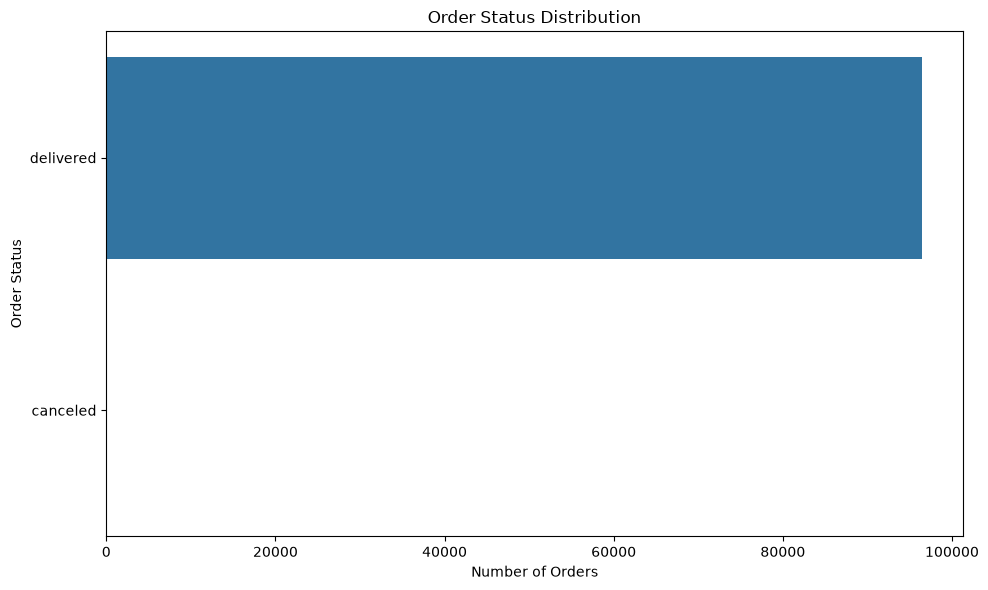

In [12]:
#What proportion of orders were canceled, unavailable or otherwise not successfully completed?

plt.figure(figsize=(10, 6))

sns.barplot(
    data=order_status,
    x="order_count",
    y="order_status"
)

plt.title("Order Status Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Order Status")

plt.tight_layout()

plt.savefig(
    Chart_Path / "01_order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
#order cancellation rate?

total_orders = len(orders)

canceled_orders = (
    orders["order_status"] == "canceled"
).sum()

cancellation_rate = (
    canceled_orders / total_orders
) * 100

print(f"Total orders: {total_orders:,}")
print(f"Canceled orders: {canceled_orders:,}")
print(f"Cancellation rate: {cancellation_rate:.2f}%")

Total orders: 96,461
Canceled orders: 6
Cancellation rate: 0.01%


In [14]:
sales = order_items.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ],
    on="order_id",
    how="left" #Every order item should remain in our sales dataset.
)

print("Sales dataset created.")
print(sales.shape)

Sales dataset created.
(112650, 10)


In [15]:
sales["revenue"] = sales["price"]

sales["freight_cost"] = sales["freight_value"]

sales["total_item_value"] = (
    sales["price"] +
    sales["freight_value"]
)                                             #Revenue = product price

print(
    sales[
        [
            "price",
            "freight_value",
            "revenue",
            "total_item_value"
        ]
    ].head()
)

    price  freight_value  revenue  total_item_value
0   58.90          13.29    58.90             72.19
1  239.90          19.93   239.90            259.83
2  199.00          17.87   199.00            216.87
3   12.99          12.79    12.99             25.78
4  199.90          18.14   199.90            218.04


In [16]:
#Total revenue

total_revenue = sales["revenue"].sum()

print(
    f"Total product revenue: "
    f"{total_revenue:,.2f}"
)

Total product revenue: 13,591,643.70


In [17]:
#Total freight

total_freight = sales["freight_cost"].sum()

print(
    f"Total freight value: "
    f"{total_freight:,.2f}"
)

Total freight value: 2,251,909.54


In [18]:
#Avg order value

order_values = (
    sales
    .groupby("order_id", as_index=False)
    .agg(
        order_revenue=("revenue", "sum"),
        order_freight=("freight_cost", "sum")
    )
)

order_values["order_total_value"] = (
    order_values["order_revenue"] +
    order_values["order_freight"]
)

average_order_value = (
    order_values["order_revenue"].mean()
)

print(
    f"Average Order Value: "
    f"{average_order_value:,.2f}"
)
order_values.head()



Average Order Value: 137.75


,order_id,order_revenue,order_freight,order_total_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04


In [19]:
#Time-Based Demand Analysis

orders["purchase_date"] = (
    orders["order_purchase_timestamp"].dt.date
)

orders["purchase_year"] = (
    orders["order_purchase_timestamp"].dt.year
)

orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.month
)

orders["purchase_month_name"] = (
    orders["order_purchase_timestamp"].dt.month_name()
)

orders["purchase_day"] = (
    orders["order_purchase_timestamp"].dt.day
)

orders["purchase_day_name"] = (
    orders["order_purchase_timestamp"].dt.day_name()
)

orders["purchase_hour"] = (
    orders["order_purchase_timestamp"].dt.hour
)

print("Time features created.")

Time features created.


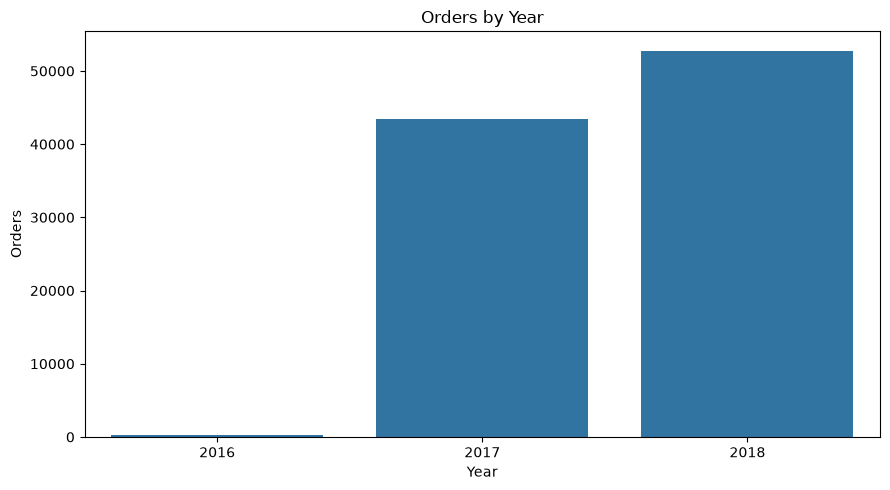

In [20]:
orders_by_year = (
    orders
    .groupby("purchase_year")
    .size()
    .reset_index(name="order_count")
)

orders_by_year

plt.figure(figsize=(9, 5))

sns.barplot(
    data=orders_by_year,
    x="purchase_year",
    y="order_count"
)

plt.title("Orders by Year")
plt.xlabel("Year")
plt.ylabel("Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path / "02_orders_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
monthly_orders = (
    orders
    .set_index("order_purchase_timestamp")
    .resample("MS")
    .size()
    .reset_index(name="order_count")
)

monthly_orders.head()

,order_purchase_timestamp,order_count
0,2016-09-01,1
1,2016-10-01,270
2,2016-11-01,0
3,2016-12-01,1
4,2017-01-01,748


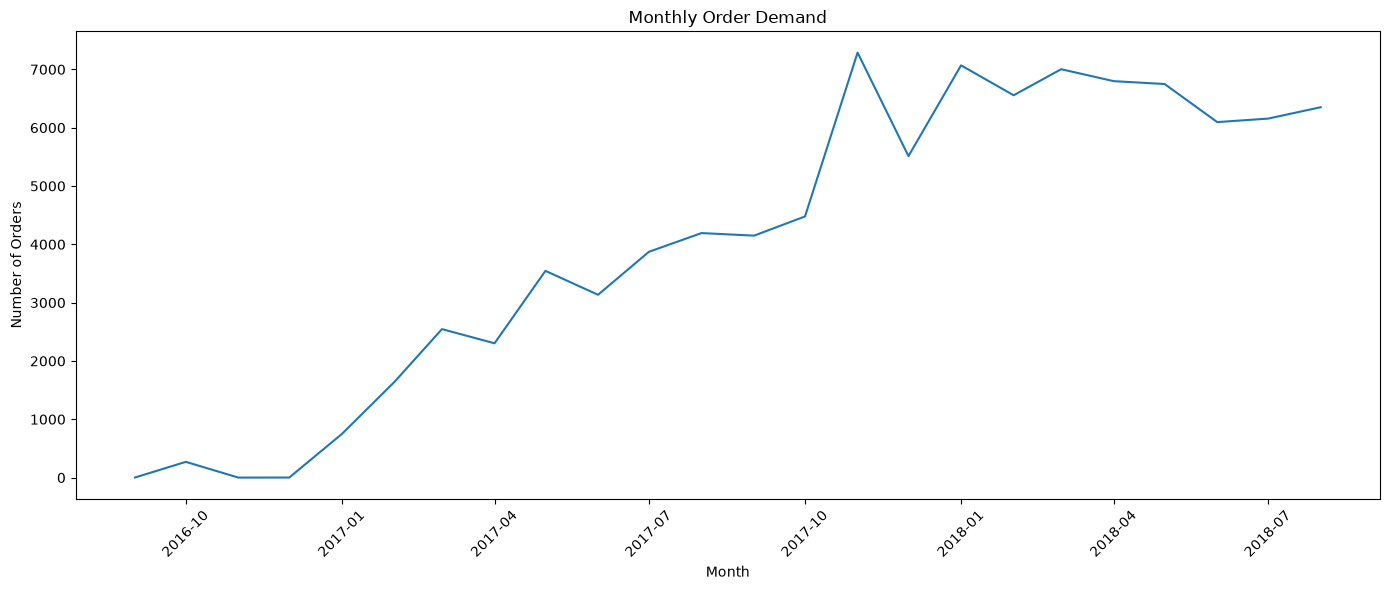

In [22]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_orders,
    x="order_purchase_timestamp",
    y="order_count"
)

plt.title("Monthly Order Demand")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    Chart_Path / "03_monthly_order_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

orders_by_day = (
    orders["purchase_day_name"]
    .value_counts()
    .reindex(day_order)
    .reset_index()
)

orders_by_day.columns = [
    "day",
    "order_count"
]

orders_by_day

,day,order_count
0,Monday,15703
1,Tuesday,15502
2,Wednesday,15074
3,Thursday,14320
4,Friday,13681
5,Saturday,10548
6,Sunday,11633


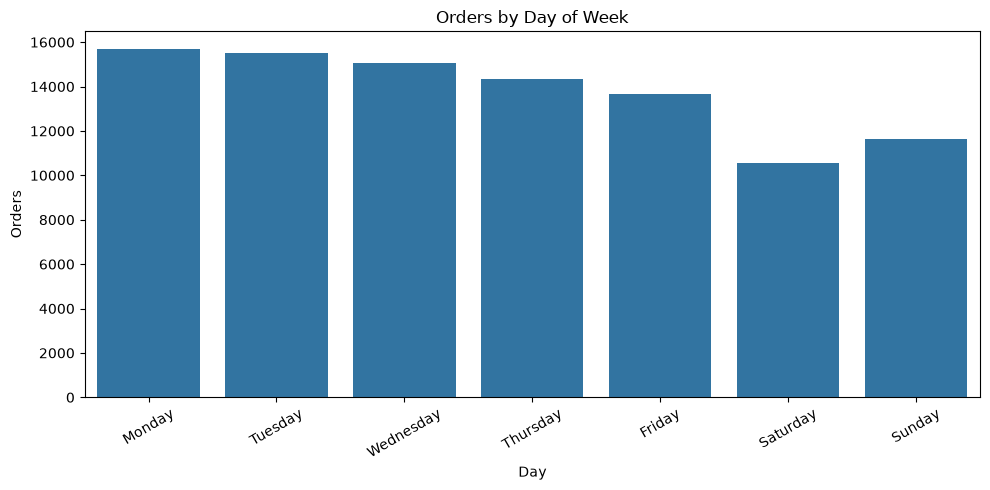

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=orders_by_day,
    x="day",
    y="order_count"
)

plt.title("Orders by Day of Week")
plt.xlabel("Day")
plt.ylabel("Orders")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    Chart_Path / "04_orders_by_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
orders_by_hour = (
    orders["purchase_hour"]
    .value_counts()
    .sort_index()
    .reset_index()
)

orders_by_hour.columns = [
    "hour",
    "order_count"
]

orders_by_hour

,hour,order_count
0,0,2322
1,1,1132
2,2,496
3,3,259
4,4,203
5,5,182
6,6,477
7,7,1199
8,8,2906
9,9,4647


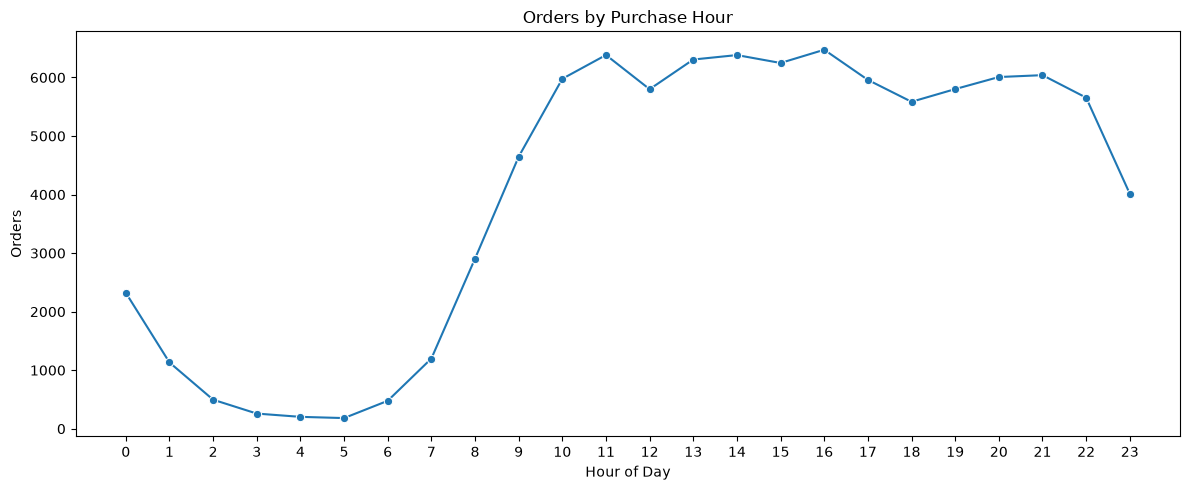

In [26]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=orders_by_hour,
    x="hour",
    y="order_count",
    marker="o"
)

plt.title("Orders by Purchase Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Orders")

plt.xticks(range(0, 24))

plt.tight_layout()

plt.savefig(
    Chart_Path / "05_orders_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
#Product Analysis

product_sales = order_items.merge(
    products[
        [
            "product_id",
            "product_category_name"
        ]
    ],
    on="product_id",
    how="left"
)

print(product_sales.shape)

(112650, 8)


In [28]:
#Top product categories by revenue

category_revenue = (
    product_sales
    .groupby("product_category_name", as_index=False)
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

category_revenue.head(10)

,product_category_name,revenue,orders,items_sold
11,beleza_saude,1258681.34,8836,9670
66,relogios_presentes,1205005.68,5624,5991
13,cama_mesa_banho,1036988.68,9417,11115
32,esporte_lazer,988048.97,7720,8641
44,informatica_acessorios,911954.32,6689,7827
54,moveis_decoracao,729762.49,6449,8334
26,cool_stuff,635290.85,3632,3796
73,utilidades_domesticas,632248.66,5884,6964
8,automotivo,592720.11,3897,4235
40,ferramentas_jardim,485256.46,3518,4347


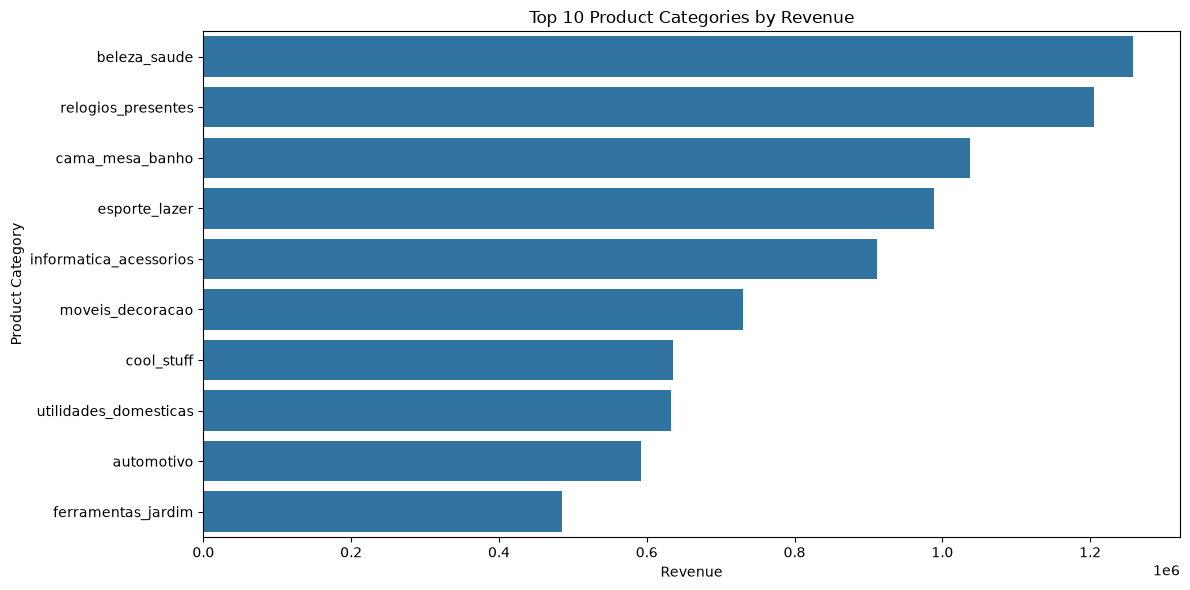

In [29]:
top_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="revenue",
    y="product_category_name"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")

plt.tight_layout()

plt.savefig(
    Chart_Path / "06_top_categories_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
top_products = (
    order_items
    .groupby("product_id", as_index=False)
    .agg(
        revenue=("price", "sum"),
        units_sold=("order_item_id", "count")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

top_products.head(10)

,product_id,revenue,units_sold
24086,bb50f2e236e5eea0100680137654686c,63885.00,195
14068,6cdd53843498f92890544667809f1595,54730.20,156
27613,d6160fb7873f184099d9bc95e30376af,48899.34,35
27039,d1c427060a0f73f6b889a5c7c61f2ac4,47214.51,343
19742,99a4788cb24856965c36a24e339b6058,43025.56,488
8051,3dd2a17168ec895c781a9191c1e95ad7,41082.60,274
4996,25c38557cf793876c5abdd5931f922db,38907.32,38
12351,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63
10867,53b36df67ebb7c41585e8d54d6772e08,37683.42,323
22112,aca2eb7d00ea1a7b8ebd4e68314663af,37608.90,527


In [31]:
#Category translation

product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

product_sales[
    [
        "product_category_name",
        "product_category_name_english"
    ]
].head()

,product_category_name,product_category_name_english
0,cool_stuff,cool_stuff
1,pet_shop,pet_shop
2,moveis_decoracao,furniture_decor
3,perfumaria,perfumery
4,ferramentas_jardim,garden_tools


In [32]:
#Unique customers

unique_customers = (
    customers["customer_unique_id"]
    .nunique()
)

print(
    f"Unique customers: "
    f"{unique_customers:,}"
)

Unique customers: 96,096


In [33]:
#Orders per customer

customer_orders = orders.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id"
        ]
    ],
    on="customer_id",
    how="left"
)

orders_per_customer = (
    customer_orders
    .groupby("customer_unique_id")
    .size()
    .reset_index(name="order_count")
)

orders_per_customer.head()

,customer_unique_id,order_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [34]:
#One-time vs repeat customers

customer_type = (
    orders_per_customer["order_count"]
    .value_counts()
    .sort_index()
)

repeat_customers = (
    orders_per_customer["order_count"] > 1
).sum()

total_unique_ordering_customers = len(
    orders_per_customer
)

repeat_customer_rate = (
    repeat_customers /
    total_unique_ordering_customers
) * 100

print(
    f"Repeat customers: {repeat_customers:,}"
)

print(
    f"Repeat customer rate: "
    f"{repeat_customer_rate:.2f}%"
)

Repeat customers: 2,800
Repeat customer rate: 3.00%


In [35]:
#Payment Analysis

payment_methods = (
    payments["payment_type"]
    .value_counts()
    .reset_index()
)

payment_methods.columns = [
    "payment_type",
    "payment_count"
]

payment_methods

,payment_type,payment_count
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3


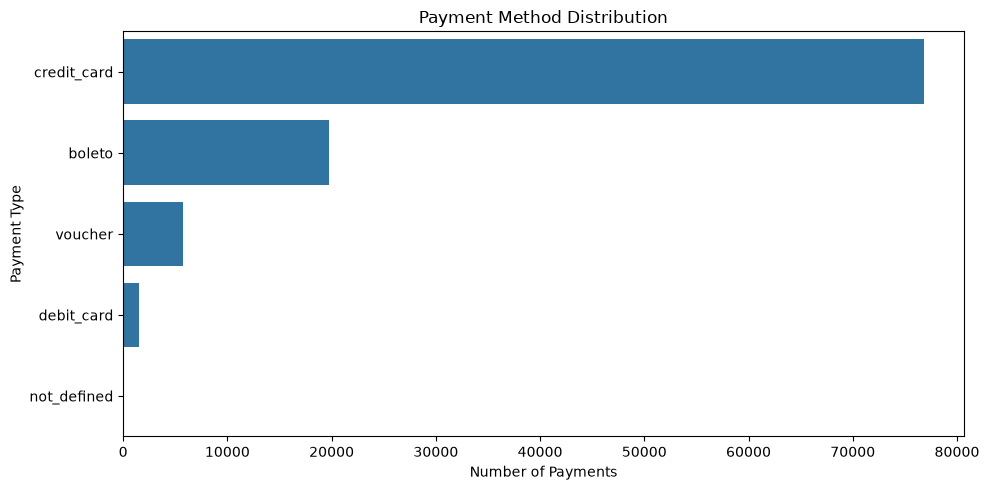

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_methods,
    x="payment_count",
    y="payment_type"
)

plt.title("Payment Method Distribution")
plt.xlabel("Number of Payments")
plt.ylabel("Payment Type")

plt.tight_layout()

plt.savefig(
    Chart_Path / "07_payment_methods.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
#Payment method

payment_value = (
    payments
    .groupby("payment_type", as_index=False)
    .agg(
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .sort_values(
        "total_payment_value",
        ascending=False
    )
)

payment_value

,payment_type,total_payment_value,average_payment_value
1,credit_card,12542084.19,163.319021
0,boleto,2869361.27,145.034435
4,voucher,379436.87,65.703354
2,debit_card,217989.79,142.570170
3,not_defined,0.00,0.000000


In [38]:
#Delivery Analysis

delivery_data = orders[
    orders["order_delivered_customer_date"].notna()
].copy()

delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

print(
    delivery_data["delivery_days"].describe()
)

count    96461.000000
mean        12.558178
std          9.546356
min          0.533414
25%          6.765856
50%         10.216308
75%         15.720255
max        209.628611
Name: delivery_days, dtype: float64


In [39]:
#Estimated vs actual delivery

delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

delivery_data["delivery_difference_days"] = (
    delivery_data["delivery_days"]
    - delivery_data["estimated_delivery_days"]
)

delivery_data[
    [
        "delivery_days",
        "estimated_delivery_days",
        "delivery_difference_days"
    ]
].head()

,delivery_days,estimated_delivery_days,delivery_difference_days
0,8.436574,15.544063,-7.107488
1,13.782037,19.137766,-5.355729
2,9.394213,26.639711,-17.245498
3,13.208750,26.188819,-12.980069
4,2.873877,12.112049,-9.238171


In [40]:
delivery_data["sla_status"] = np.select(
    [
        delivery_data["delivery_difference_days"] < 0,
        delivery_data["delivery_difference_days"] == 0,
        delivery_data["delivery_difference_days"] > 0
    ],
    [
        "Early",
        "On Time",
        "Delayed"
    ],
    default="Unknown"
)

delivery_data["sla_status"].value_counts()

sla_status
Early      88635
Delayed     7826
Name: count, dtype: int64

In [41]:
#Average delivery time

average_delivery_days = (
    delivery_data["delivery_days"].mean()
)

print(
    f"Average delivery time: "
    f"{average_delivery_days:.2f} days"
)

Average delivery time: 12.56 days


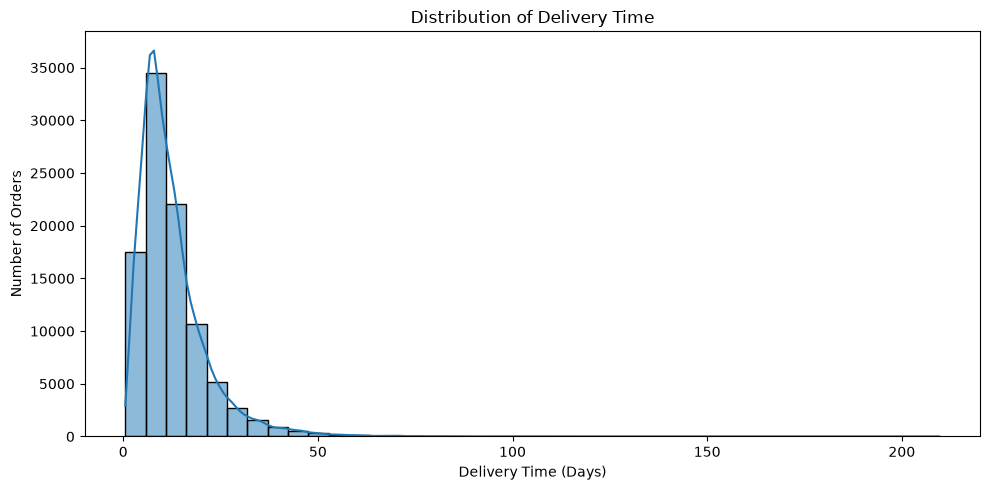

In [42]:
#Delivery distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    delivery_data["delivery_days"].dropna(),
    bins=40,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path / "08_delivery_time_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
#Review Analysis

review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = [
    "review_score",
    "review_count"
]

review_distribution

,review_score,review_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


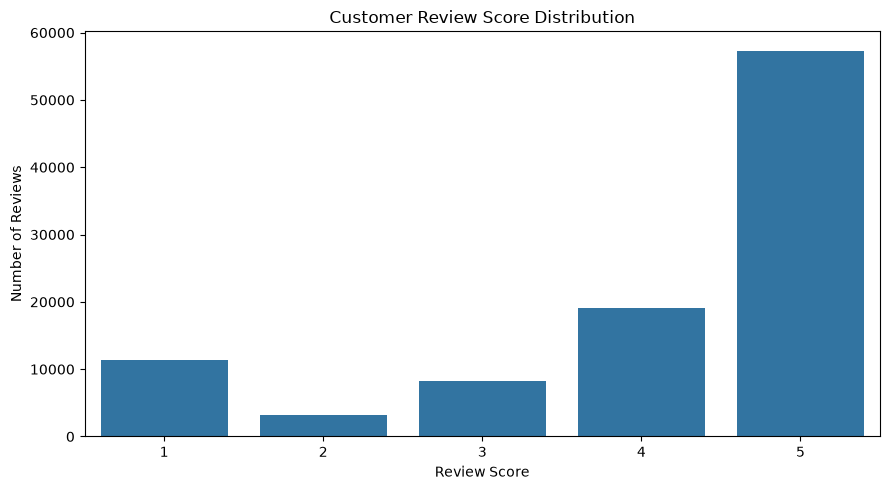

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=review_distribution,
    x="review_score",
    y="review_count"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    Chart_Path / "09_review_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
#Average review score

average_review_score = (
    reviews["review_score"].mean()
)

print(
    f"Average review score: "
    f"{average_review_score:.2f}"
)

Average review score: 4.09


In [46]:
#Does delivery delay relate to reviews?

review_delivery = delivery_data[
    [
        "order_id",
        "delivery_days",
        "delivery_difference_days"
    ]
].merge(
    reviews[
        [
            "order_id",
            "review_score"
        ]
    ],
    on="order_id",
    how="inner"
)

review_delivery.head()

,order_id,delivery_days,delivery_difference_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,4
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,4
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,5
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,5


In [47]:
review_delivery[
    [
        "delivery_days",
        "delivery_difference_days",
        "review_score"
    ]
].corr()

,delivery_days,delivery_difference_days,review_score
delivery_days,1.000000,0.601185,-0.333874
delivery_difference_days,0.601185,1.000000,-0.266482
review_score,-0.333874,-0.266482,1.000000


In [48]:
#Location Analysis

customer_location_orders = orders.merge(
    customers[
        [
            "customer_id",
            "customer_state",
            "customer_city"
        ]
    ],
    on="customer_id",
    how="left"
)

state_orders = (
    customer_location_orders
    .groupby("customer_state", as_index=False)
    .size()
    .rename(columns={"size": "order_count"})
    .sort_values(
        "order_count",
        ascending=False
    )
)

state_orders.head(10)

,customer_state,order_count
25,SP,40489
18,RJ,12351
10,MG,11352
22,RS,5342
17,PR,4923
23,SC,3547
4,BA,3256
6,DF,2080
7,ES,1995
8,GO,1957


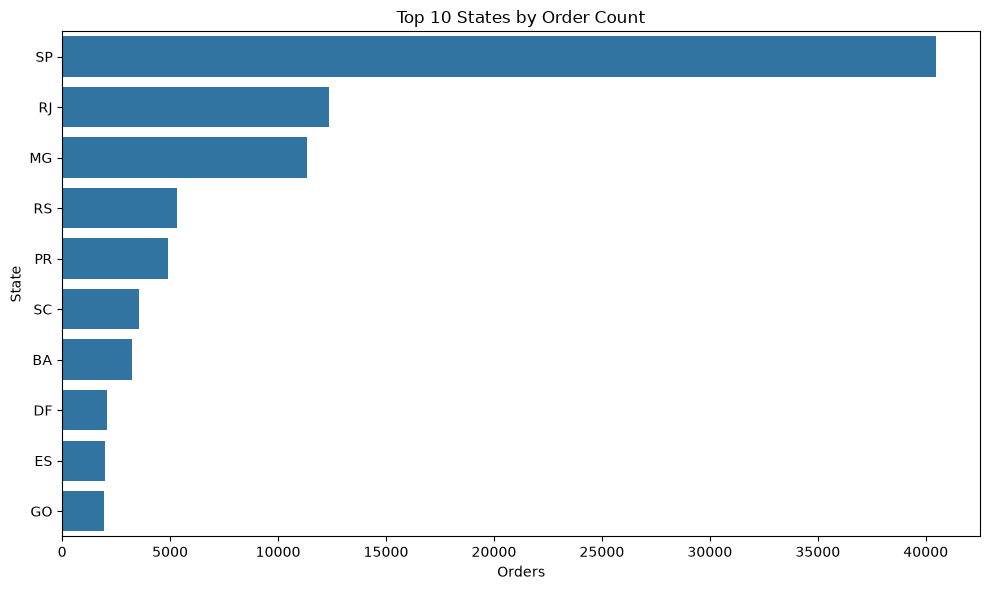

In [49]:
top_states = state_orders.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_states,
    x="order_count",
    y="customer_state"
)

plt.title("Top 10 States by Order Count")
plt.xlabel("Orders")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    Chart_Path / "10_top_states_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
#Advanced EDA — Demand Heatmap

demand_heatmap = pd.crosstab(
    orders["purchase_day_name"],
    orders["purchase_hour"]
)

demand_heatmap = demand_heatmap.reindex(day_order)

demand_heatmap

purchase_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
purchase_day_name,,,,,,,,,,,,,,,,,,,,,
Monday,315,132,63,34,21,22,64,157,471,752,...,1063,1047,1060,954,891,921,998,1084,962,697
Tuesday,300,151,79,28,28,24,69,216,510,845,...,1095,1005,1059,942,852,894,946,996,939,676
Wednesday,385,171,81,31,33,24,90,208,497,798,...,1027,952,1007,943,818,822,881,927,855,600
Thursday,345,165,74,38,30,28,82,211,495,736,...,951,901,1042,881,759,798,816,826,834,532
Friday,412,210,66,46,39,35,91,203,486,754,...,938,947,943,790,697,757,714,700,675,496
Saturday,308,167,65,41,25,23,51,102,245,421,...,649,699,675,673,693,729,709,645,534,422
Sunday,257,136,68,41,27,26,30,102,202,341,...,660,697,688,776,875,881,944,862,857,591


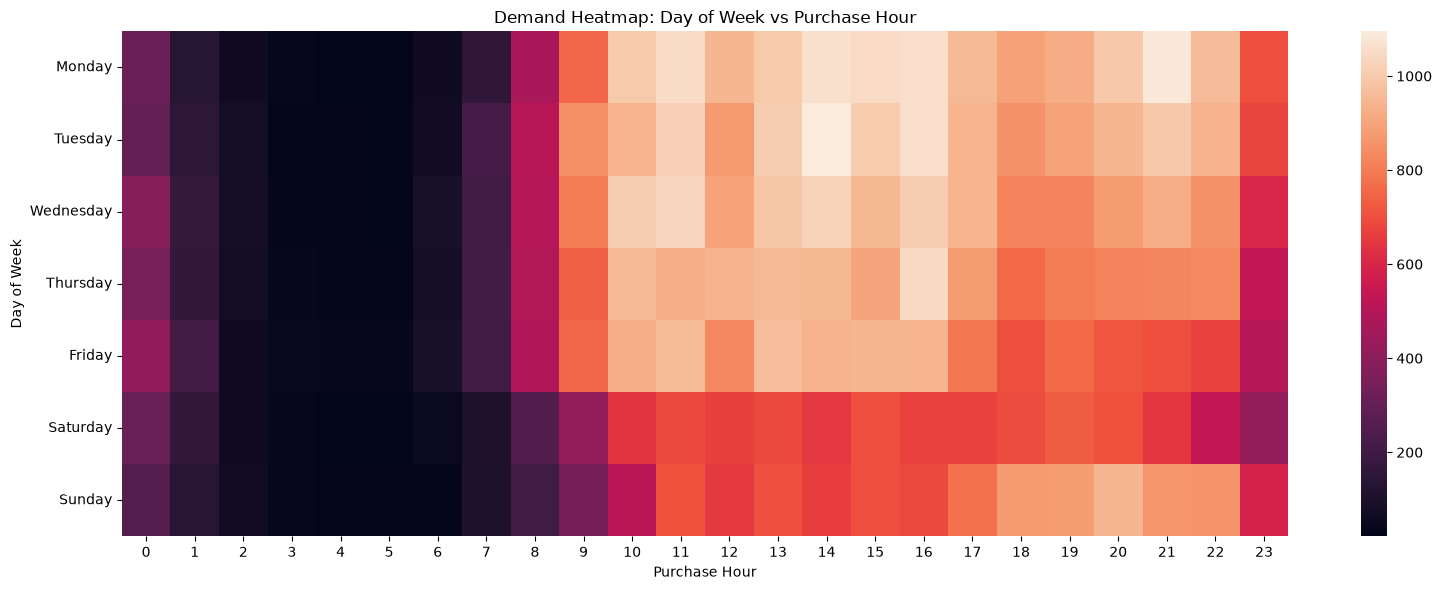

In [51]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    demand_heatmap,
    annot=False
)

plt.title("Demand Heatmap: Day of Week vs Purchase Hour")
plt.xlabel("Purchase Hour")
plt.ylabel("Day of Week")

plt.tight_layout()

plt.savefig(
    Chart_Path / "11_demand_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
#EDA KPI summary

eda_kpis = pd.DataFrame({
    "metric": [
        "Total Orders",
        "Unique Customers",
        "Total Product Revenue",
        "Total Freight",
        "Average Order Value",
        "Average Delivery Days",
        "Average Review Score",
        "Cancellation Rate",
        "Repeat Customer Rate"
    ],
    "value": [
        total_orders,
        unique_customers,
        total_revenue,
        total_freight,
        average_order_value,
        average_delivery_days,
        average_review_score,
        cancellation_rate,
        repeat_customer_rate
    ]
})

eda_kpis

,metric,value
0,Total Orders,9.646100e+04
1,Unique Customers,9.609600e+04
2,Total Product Revenue,1.359164e+07
3,Total Freight,2.251910e+06
4,Average Order Value,1.377541e+02
5,Average Delivery Days,1.255818e+01
6,Average Review Score,4.086421e+00
7,Cancellation Rate,6.220130e-03
8,Repeat Customer Rate,2.999721e+00


In [53]:
eda_kpis.to_csv(
    Table_Path / "eda_kpi_summary.csv",
    index=False
)

print("EDA KPI summary saved successfully.")

EDA KPI summary saved successfully.
